In [2]:
%run ./dataManipulationFunctions.ipynb

## Attempt to create a model with determines gender based on Big five Traits using the average per clip as features and gender as result

Text(0.5, 1.0, 'Frequency of Classes Male vs Female')

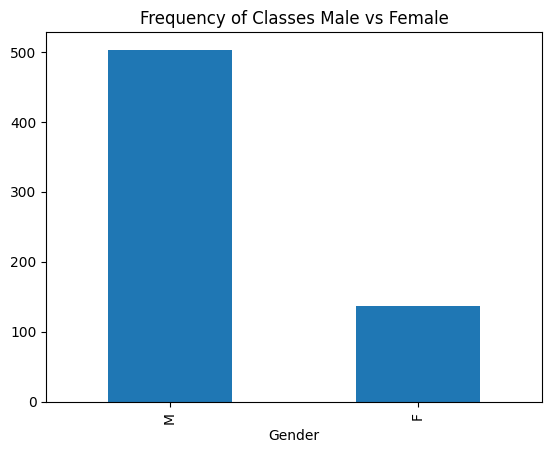

In [21]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

# df = pd.DataFrame(medianScoresPerClip(), columns=columns)
array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
df.head()

dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
ax = df.Gender.value_counts().plot(kind='bar')
ax.set_title('Frequency of Classes Male vs Female')

In [5]:
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

2023-12-01 16:26:12.987345: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Encode 'M' and 'F' into 0 and 1 using labelEncoder

In [6]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0]
#MALE - 0, FEMALE - 1

### Splitting dataset

Splitting dataset into train and test subsets

* Can use train_test_split once to split database once 
* Can use train_test_split twice, first to split into train and test set and a second time to split the train set into validation and train

Validation set
* used for unbiased model evaluation during hyperparameter tuning

train_test_split Parameters
* arrays of features and target values
* test_size - 0.0-1.0, the proportion of the dataset to include in the test split (None --> 0.25)
* random_state - controls the shuffling applied to data before applying the split - int passed = reproduceable output across multiple function calls
* stratify - set contains approximately the same percentage of samples of each tagret class

In [7]:
from sklearn.model_selection import train_test_split
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
# Splitting the dataset into train and test sets - with test size = 30% 
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=34)
# PARAMETER  stratify=y

# print(pd.DataFrame(y_test).value_counts())


Second split of the subset X_train & y_train into train and validation sets

In [8]:
X_train2,X_val,y_train2,y_val=train_test_split(X_train,y_train,test_size=0.3,random_state=1)
# PARAMETER  stratify=y

# print(pd.DataFrame(y_val).value_counts())

In [9]:
#SPLITTING TRAIN TEST INTO SETS FOR TRAIN & VALIDATION

from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=1)
for i, (train_index, test_index) in enumerate(sss.split(X_train, y_train)):
    print(i, train_index.shape, test_index.shape)
    # MODEL FIT & PREDICT ETC.

0 (358,) (90,)
1 (358,) (90,)
2 (358,) (90,)
3 (358,) (90,)
4 (358,) (90,)


In [10]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [11]:
#Using k fold validation - uses multiple substets for training and testing 
#   The data is partitioned in k equally sized subsets(folds) & train the model k times & rest for testing 

#StratifiedKFold --> provides indices to split sets - returns stratified folds = 
# folds are preserving percentages of samples for each class
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, confusion_matrix

skfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=37)

lr_listOverFolds=[]
rfc_listOverFolds=[]
for train_index, test_index in skfold.split(X, y):
    # print('train -  {}   |   test -  {}'.format( np.bincount(y_train), np.bincount(y_test)))
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    # EACH SET OF TESTS HAS ABOUT 50-51 M and 13-14 F

# Logistic Regression
    lr_model = LogisticRegression(penalty='l2', solver='liblinear', random_state=37)
    lr_model.fit(X_train, y_train)
    lr_pred = lr_model.predict(X_test)
    lr_averagePrecisionScore = average_precision_score(y_test, lr_pred)

    lr_listOverFolds.append({'f1 Score': f1_score(y_test, lr_pred), 'Confusion Matrix': confusion_matrix(y_test, lr_pred),'averagePrecisionScore': lr_averagePrecisionScore})

    rfc_model = RandomForestClassifier(n_jobs=-1, random_state=37)
    rfc_model.fit(X_train, y_train)
    rfc_y_predicted = rfc_model.predict_proba(X_test)[:,1]
    # print(model.score(X_test, y_test))
    
    rfc_areaUnderCurve = roc_auc_score(y_test, rfc_y_predicted)
    rfc_averagePrecisionScore = average_precision_score(y_test, rfc_y_predicted)
    rfc_listOverFolds.append({'areaUnderCurve': rfc_areaUnderCurve, 'averagePrecisionSocre': rfc_averagePrecisionScore})


#AVERAGE PRECISION SCORE - used for binary classification problems - when dealing with imbalanced datastes
# it summarizes a precision-recall curve 
    rfc_areaUnderCurve = roc_auc_score(y_test, rfc_y_predicted)
    rfc_averagePrecisionScore = average_precision_score(y_test, rfc_y_predicted)
    rfc_listOverFolds.append({'areaUnderCurve': rfc_areaUnderCurve, 'averagePrecisionScore': rfc_averagePrecisionScore})

lr_listOverFolds = pd.DataFrame(lr_listOverFolds)
rfc_listOverFolds = pd.DataFrame(rfc_listOverFolds)
# print(listOverFoldsf)

display(lr_listOverFolds[['f1 Score', 'Confusion Matrix', 'averagePrecisionScore']])
print(lr_listOverFolds[['f1 Score', 'averagePrecisionScore']].agg(['mean', 'std']))

display(rfc_listOverFolds[['areaUnderCurve', 'averagePrecisionScore']].agg(['mean', 'std']))

,f1 Score,Confusion Matrix,averagePrecisionScore
0,0.352941,"[[50, 1], [10, 3]]",0.329327
1,0.000000,"[[49, 2], [13, 0]]",0.203125
2,0.222222,"[[48, 3], [11, 2]]",0.233413
3,0.352941,"[[50, 0], [11, 3]]",0.386161
4,0.400000,"[[48, 2], [10, 4]]",0.346726
5,0.235294,"[[49, 1], [12, 2]]",0.282738
6,0.400000,"[[48, 2], [10, 4]]",0.346726
7,0.500000,"[[49, 1], [9, 5]]",0.438244
8,0.500000,"[[49, 1], [9, 5]]",0.438244
9,0.200000,"[[46, 4], [12, 2]]",0.235119


      f1 Score  averagePrecisionScore
mean  0.316340               0.323982
std   0.153902               0.083963


,areaUnderCurve,averagePrecisionScore
mean,0.675625,0.414375
std,0.066107,0.092787


In [12]:
from sklearn.tree import DecisionTreeClassifier

dtc_clf = DecisionTreeClassifier(class_weight={0:3,1:1})
dtc_clf = dtc_clf.fit(X_train,y_train)
dtc_prediction = dtc_clf.predict(X_test)
# print (dtc_prediction)
score_lr=cross_val_score(DecisionTreeClassifier(), X, y,cv=5)
print(score_lr)
print("Avg :",np.average(score_lr))


[0.7421875 0.7578125 0.8125    0.734375  0.7578125]
Avg : 0.7609375


In [13]:
from sklearn.ensemble import RandomForestClassifier
#RandomForestClassifier
rfc_clf = RandomForestClassifier(class_weight={0:3,1:1})
rfc_clf.fit(X_train,y_train)
rfc_prediction = rfc_clf.predict(X_test)
# print (rfc_prediction)

score_rf=cross_val_score(RandomForestClassifier(n_estimators=40),X, y,cv=5)
print(score_rf)
print("Avg :",np.average(score_rf))


[0.7734375 0.6953125 0.796875  0.7578125 0.78125  ]
Avg : 0.7609375


In [14]:
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(class_weight={0:3,1:1})
lr_clf.fit(X_train,y_train)
lr_prediction = lr_clf.predict(X_test)
# print (lr_prediction)

from sklearn.model_selection import cross_val_score
score_lr=cross_val_score(LogisticRegression(solver='liblinear',multi_class='ovr'), X, y,cv=5)
print(score_lr)
print("Avg :",np.average(score_lr))

[0.8125    0.75      0.828125  0.8046875 0.796875 ]
Avg : 0.7984375


In [15]:
from sklearn.tree import DecisionTreeClassifier
#Support Vector Classifier
knn = KNeighborsClassifier(n_neighbors=8)
knn.fit(X_train, y_train)
knn_prediction = knn.predict(X_test)
# print (knnPrediction)

scoreKnn=cross_val_score(knn, X, y,cv=5)
print(scoreKnn)
print("Avg :",np.average(scoreKnn))

[0.7890625 0.7890625 0.78125   0.8125    0.7890625]
Avg : 0.7921875


In [16]:
# from sklearn.metrics import PrecisionRecallDisplay
# display = PrecisionRecallDisplay.from_estimator(
#     knn, X_test, y_test, name="knn", plot_chance_level=True
# )
# _ = display.ax_.set_title("2-class Precision-Recall curve")

# y_score = knn.decision_function(X_test)

# display = PrecisionRecallDisplay.from_predictions(
#     y_test, y_score, name="knn", plot_chance_level=True
# )
# _ = display.ax_.set_title("2-class Precision-Recall curve")

In [17]:
stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
crossStratified= cross_val_score(knn, X, y, cv=stratified)
print(crossStratified)

[0.8046875 0.828125  0.7890625 0.7578125 0.796875 ]


In [18]:
from sklearn.svm import SVC
#Support Vector Classifier
s_clf = SVC(class_weight={0:3,1:1})
s_clf.fit(X_train,y_train)
s_prediction = s_clf.predict(X_test)
# print (s_prediction)

score_svm=cross_val_score(SVC(gamma='auto'), X, y,cv=5)
print(score_svm)
print("Avg :",np.average(score_svm))

[0.796875  0.765625  0.796875  0.78125   0.7890625]
Avg : 0.7859375


In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

#ACCURACY SCORE
dtc_tree_acc = accuracy_score(dtc_prediction,y_test)
rfc_acc = accuracy_score(rfc_prediction,y_test)
l_acc = accuracy_score(lr_prediction,y_test)
s_acc = accuracy_score(s_prediction,y_test)
knn_acc =  accuracy_score(knn_prediction,y_test)

#CONFUSION MATRIX
dtc_tree_conf = confusion_matrix(y_test, dtc_prediction)
rfc_conf = confusion_matrix(y_test,rfc_prediction)
l_conf = confusion_matrix(y_test,lr_prediction)
s_conf = confusion_matrix(y_test, s_prediction)
knn_conf =  confusion_matrix(y_test, knn_prediction)

#PRECISION SCORE
dtc_tree_prec = precision_score(y_test, dtc_prediction)
rfc_prec = precision_score(y_test, rfc_prediction)
l_prec = precision_score(y_test, lr_prediction)
s_prec = precision_score(y_test, s_prediction)
knn_prec =  precision_score(y_test, knn_prediction)

#RECALL SCORE
dtc_tree_rec = recall_score(y_test, dtc_prediction)
rfc_rec = recall_score(y_test, rfc_prediction)
l_rec = recall_score(y_test, lr_prediction)
s_rec = recall_score(y_test, s_prediction)
knn_rec =  recall_score(y_test, knn_prediction)

#F1 SCORE
dtc_tree_f1 = f1_score(y_test, dtc_prediction)
dtc_tree_f1 = f1_score(y_test, rfc_prediction)
l_f1 = f1_score(y_test, lr_prediction)
s_f1 = f1_score(y_test, s_prediction)
knn_f1 =  f1_score(y_test, knn_prediction)

classifiers = ['Decision Tree', 'Random Forest', 'Logistic Regression' , 'SVC', 'KNN']

accuracy = np.array([dtc_tree_acc, rfc_acc, l_acc, s_acc, knn_acc])
confusionMatrix = np.array([dtc_tree_conf,rfc_conf,l_conf, s_conf, knn_conf ])
precisionScore = np.array([dtc_tree_prec, rfc_prec, l_prec, s_prec, knn_prec])
recallScore = np.array([dtc_tree_rec, rfc_rec, l_rec, s_rec, knn_rec])
f1Score = np.array([dtc_tree_f1, dtc_tree_f1, l_f1, s_f1, knn_f1])
print(accuracy)
# print(confusionMatrix)
# print(precisionScore)
# print(recallScore)
print(f1Score)

# max_acc = np.argmax(accuracy)

print(classifiers[np.argmax(f1Score)] + ' is the best classifier with high f1 score: ' + str(f1Score[np.argmax(f1Score)]) )

afterFold = np.array([0, np.average(score_rf), np.average(score_lr), np.average(score_svm)])
# max_acc_afterFold = np.argmax(afterFold)
# print('After kFold: ', afterFold, str(classifiers[max_acc_afterFold]), ' is the best classifier')
# print(str(accuracy[max_acc]))


[0.6875   0.765625 0.75     0.78125  0.75    ]
[0.34782609 0.34782609 0.         0.         0.11111111]
Decision Tree is the best classifier with high f1 score: 0.34782608695652173


/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


### Binomial Test

In [20]:
from scipy import stats

model = 4
print(confusionMatrix[model])
total = y_test.size
truePositives = confusionMatrix[model][0][0] #correct male
trueNegatives = confusionMatrix[model][0][1] #wrong male
FalsePositives = confusionMatrix[model][1][0] #wrong female
FalseNegatives = confusionMatrix[model][1][1]  #correct female

pred = (truePositives + trueNegatives) / total

femaleProb = (FalsePositives + FalseNegatives) /total
maleProb = (truePositives + trueNegatives)/total

p = ((femaleProb**2) + (maleProb**2))
# Parameters -> number of successes, n - number of trials (test set?)

#alternative - 'two-sided' = two sided test, 'greater' = if number of successes is greater than expected, 'less' = if less than expected
result = stats.binomtest((truePositives + trueNegatives), n=total, p=p, alternative='two-sided')
result.pvalue

[[47  3]
 [13  1]]


0.04706126306999808